# Budget vs. Actual: Will We Finish the Year on Budget?

It's the end of September 2026. Finance wants to know which departments will finish the year
over or under budget. This notebook:

1. Cleans the data (with SQL)
2. Finds where spending has differed from budget
3. Forecasts October–December spending three ways and picks the most accurate
4. Lists which departments need attention

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

df = pd.read_csv("budget_data.csv")
df.head()

,month,department,budget,actual
0,2023-01,Engineering,500000,507451.0
1,2023-01,Sales,200000,223071.0
2,2023-01,Marketing,150000,152915.0
3,2023-01,Support,120000,125483.0
4,2023-01,Operations,100000,99298.0


## 1. Clean the data

First, look for problems.

In [2]:
print("Duplicate rows:", df.duplicated().sum())
print("Past months with no actual:", (df["actual"].isna() & (df["month"] <= "2026-09")).sum())
df["department"].value_counts()

Duplicate rows: 1
Past months with no actual: 1


department
Engineering    49
Sales          48
Support        48
Operations     48
Marketing      47
Marketng        1
Name: count, dtype: int64

Three problems: one duplicated row, one past month missing its actual, and one row where
"Marketing" is misspelled "Marketng". `clean.sql` fixes all three. We load the CSV into a small
SQLite database, run the SQL, and read the clean table back.

In [3]:
con = sqlite3.connect(":memory:")
df.to_sql("raw", con, index=False)
con.executescript(open("clean.sql").read())
clean = pd.read_sql("SELECT * FROM clean ORDER BY month, department", con)

print(len(df), "rows before cleaning,", len(clean), "rows after")
clean["department"].value_counts()

241 rows before cleaning, 240 rows after


department
Engineering    48
Marketing      48
Operations     48
Sales          48
Support        48
Name: count, dtype: int64

## 2. Where has spending differed from budget?

In [4]:
clean["year"] = clean["month"].str[:4]
past = clean[clean["actual"].notna()]          # only months that have happened

yearly = past.groupby(["department", "year"])[["budget", "actual"]].sum()
yearly["variance_%"] = ((yearly["actual"] - yearly["budget"]) / yearly["budget"] * 100).round(1)
table = yearly["variance_%"].unstack()
table      # 2026 is January-September only

year,2023,2024,2025,2026
department,,,,
Engineering,0.0,-0.6,0.7,0.8
Marketing,0.2,-0.1,0.2,23.1
Operations,-1.0,14.5,0.6,-0.9
Sales,11.7,13.5,12.1,11.1
Support,-1.3,0.7,-0.3,-15.9


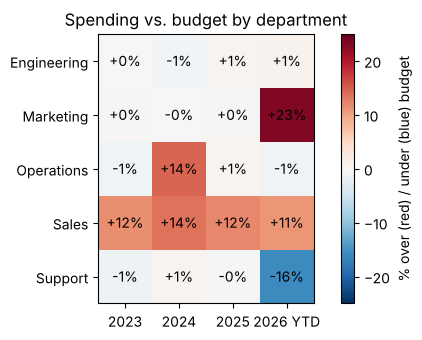

In [5]:
plt.figure(figsize=(7, 3.5))
plt.imshow(table, cmap="RdBu_r", vmin=-25, vmax=25)
plt.xticks(range(len(table.columns)), ["2023", "2024", "2025", "2026 YTD"])
plt.yticks(range(len(table.index)), table.index)
for row in range(len(table.index)):
    for col in range(len(table.columns)):
        plt.text(col, row, f"{table.iloc[row, col]:+.0f}%", ha="center", va="center")
plt.colorbar(label="% over (red) / under (blue) budget")
plt.title("Spending vs. budget by department")
plt.show()

What the heatmap shows:
- **Sales** is about 12% over budget **every year**. That's not bad luck; the budget is unrealistic, or spending needs tighter control.
- **Operations** was 14.5% over in 2024 and back to normal in 2025: a **one-time** event. The monthly data puts it in June–July 2024 (worth asking Operations what happened).
- **Marketing** is 23% over in 2026, a **new** problem this year.
- **Support** is 16% under in 2026, also new this year.
- **Engineering**, the biggest budget, stays within about 1% every year.

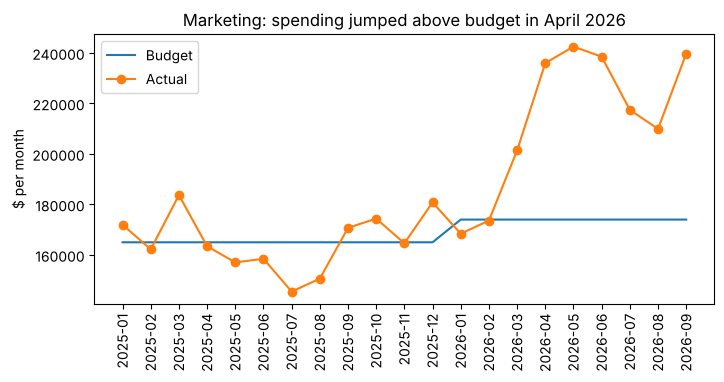

In [6]:
marketing = past[(past["department"] == "Marketing") & (past["year"] >= "2025")]

plt.figure(figsize=(8, 3.5))
plt.plot(marketing["month"], marketing["budget"], label="Budget")
plt.plot(marketing["month"], marketing["actual"], label="Actual", marker="o")
plt.xticks(rotation=90)
plt.ylabel("$ per month")
plt.title("Marketing: spending jumped above budget in April 2026")
plt.legend()
plt.show()

## 3. Forecast October–December

For each department and year, we need two numbers: spending in **Jan–Sep** (known by September)
and spending in **Oct–Dec** (what we want to predict).

In [7]:
clean["period"] = "Jan-Sep"
clean.loc[clean["month"].str[5:] >= "10", "period"] = "Oct-Dec"

jan_sep = clean[clean["period"] == "Jan-Sep"].groupby(["department", "year"])["actual"].sum()
oct_dec = clean[clean["period"] == "Oct-Dec"].groupby(["department", "year"])["actual"].sum()
budget = clean.groupby(["department", "year"])["budget"].sum()

data = pd.DataFrame({"jan_sep": jan_sep.astype(int), "oct_dec": oct_dec, "budget": budget}).reset_index()
data.loc[data["year"] == "2026", "oct_dec"] = None    # not known yet
data

,department,year,jan_sep,oct_dec,budget
0,Engineering,2023,4472633,1528870.0,6000000
1,Engineering,2024,4679031,1582380.0,6300000
2,Engineering,2025,4970550,1687026.0,6612000
3,Engineering,2026,5254015,NaN,6948000
4,Marketing,2023,1345017,457750.0,1800000
5,Marketing,2024,1417059,477195.0,1896000
6,Marketing,2025,1463573,519812.0,1980000
7,Marketing,2026,1927556,NaN,2088000
8,Operations,2023,881547,305877.0,1200000
9,Operations,2024,1121317,321896.0,1260000


Three ways to predict Oct–Dec:

| Method | Idea |
|---|---|
| **Run-rate** | Oct–Dec will be 3 average months: Jan–Sep ÷ 9 × 3. This is what most finance teams do. |
| **Last year's pattern** | Oct–Dec will be the same size relative to Jan–Sep as it was last year. |
| **Linear regression (ML)** | Learn the relationship between Jan–Sep and Oct–Dec from past years. |

To see which works best, we **backtest**: pretend it's September 2025, predict Oct–Dec 2025
using only 2023–2024 data, and compare with what actually happened.

In [8]:
train = data[data["year"] < "2025"]
test = data[data["year"] == "2025"].copy()
last_year = data[data["year"] == "2024"]

# Method 1: run-rate
test["run_rate"] = test["jan_sep"] / 9 * 3

# Method 2: last year's pattern
ratio = last_year["oct_dec"].values / last_year["jan_sep"].values
test["last_year"] = test["jan_sep"] * ratio

# Method 3: linear regression
model = LinearRegression()
model.fit(train[["jan_sep"]], train["oct_dec"])
test["regression"] = model.predict(test[["jan_sep"]])

test[["department", "oct_dec", "run_rate", "last_year", "regression"]].round()

,department,oct_dec,run_rate,last_year,regression
2,Engineering,1687026.0,1656850.0,1680967.0,1689851.0
6,Marketing,519812.0,487858.0,492859.0,493782.0
10,Operations,343351.0,328354.0,282781.0,330584.0
14,Sales,751668.0,735694.0,756524.0,747359.0
18,Support,401879.0,392584.0,418356.0,396302.0


In [9]:
for method in ["run_rate", "last_year", "regression"]:
    error = (test[method] - test["oct_dec"]).abs().sum()
    print(f"{method:12} total error: ${error:,.0f}")

run_rate     total error: $102,396
last_year    total error: $114,915
regression   total error: $51,509


**Linear regression had about half the error of the run-rate method**, so it's the one we use.

Last year's pattern did worst, mainly because of Operations: the one-time 2024 spike made 2024 a
misleading guide for 2025. Keep in mind this test covers only one year and five departments, so it
supports the choice of model rather than proving it.

## 4. Forecast 2026

In [10]:
forecast = data[data["year"] == "2026"].copy()

model = LinearRegression()
model.fit(data[data["year"] < "2026"][["jan_sep"]], data[data["year"] < "2026"]["oct_dec"])
forecast["oct_dec"] = model.predict(forecast[["jan_sep"]]).round().astype(int)

forecast["year_end"] = forecast["jan_sep"] + forecast["oct_dec"]
forecast["variance"] = forecast["year_end"] - forecast["budget"]
forecast["variance_%"] = (forecast["variance"] / forecast["budget"] * 100).round(1)
forecast["status"] = "On track"
forecast.loc[forecast["variance_%"] > 5, "status"] = "Over budget"
forecast.loc[forecast["variance_%"] < -5, "status"] = "Under budget"

forecast = forecast[["department", "budget", "jan_sep", "year_end", "variance", "variance_%", "status"]]
forecast

,department,budget,jan_sep,year_end,variance,variance_%,status
3,Engineering,6948000,5254015,7038898,90898,1.3,On track
7,Marketing,2088000,1927556,2582847,494847,23.7,Over budget
11,Operations,1392000,1035106,1387341,-4659,-0.3,On track
15,Sales,2784000,2319737,3108204,324204,11.6,Over budget
19,Support,1668000,1051655,1409510,-258490,-15.5,Under budget


Company budget:    $14,880,000
Forecast year-end: $15,526,800
Variance:          $646,800


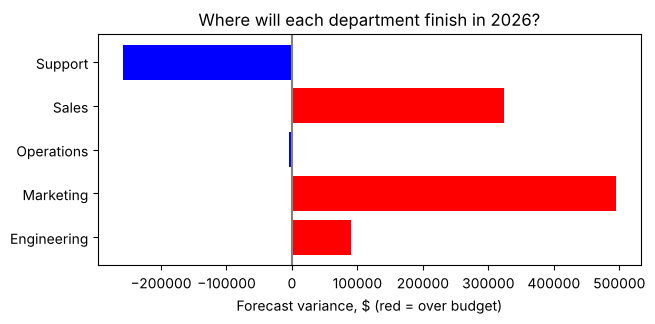

In [11]:
print(f"Company budget:    ${forecast['budget'].sum():,.0f}")
print(f"Forecast year-end: ${forecast['year_end'].sum():,.0f}")
print(f"Variance:          ${forecast['variance'].sum():,.0f}")

colors = ["red" if v > 0 else "blue" for v in forecast["variance"]]
plt.figure(figsize=(7, 3))
plt.barh(forecast["department"], forecast["variance"], color=colors)
plt.axvline(0, color="gray")
plt.xlabel("Forecast variance, $ (red = over budget)")
plt.title("Where will each department finish in 2026?")
plt.show()

## Findings and recommendations

The company is forecast to finish 2026 about **$647K (4.3%) over its $14.9M budget**.

| Department | Forecast | What to do |
|---|---|---|
| Marketing | $495K over (+24%) | Find out whether the extra campaign spending continues through December. |
| Sales | $324K over (+12%) | Fourth year in a row. Set a realistic budget for 2027 or tighten spending. |
| Support | $258K under (−16%) | The hiring freeze frees up money that could cover part of the Marketing overrun. |
| Engineering, Operations | Within 1.5% | No action needed. |

## 5. Save the results

The forecast goes to a CSV (for Excel or Power BI) and into the dashboard.

In [12]:
forecast.to_csv("forecast_2026.csv", index=False)

page = open("dashboard_template.html").read()
page = page.replace("FORECAST_DATA", forecast.to_json(orient="records"))
open("dashboard.html", "w").write(page)
print("Saved forecast_2026.csv and dashboard.html")

Saved forecast_2026.csv and dashboard.html
